In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pywt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import sys
import os

from wavelets import WaveletTransformOperator2D

import jlinops




from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])



from msolver import IASGKS, MM2019GKS, VanillaGKS # 2019 weights
from fsolver import MM2019FGK, IASFGK # 2019 weights
from f2019solver import MM2019FGK2019, IASFGK2019 # 2019 iterative method (ends in 2019)
from pgkbsolver import MM2019GKB, IASGKB

# Setup toy problem

In [2]:
image = jlinops.cameraman()
img_shape = image.shape
ground_truth = image.flatten()

A = jlinops.Gaussian2DBlurOperator(img_shape, blur_sigma=2.0, mode="reflect")
#A = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
b_true = A @ ground_truth
noise_level_sigma = 0.03
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
noise_sigma = np.sqrt(noise_var)
b = b_true + noise_vec
naive_recon = A.T @ b

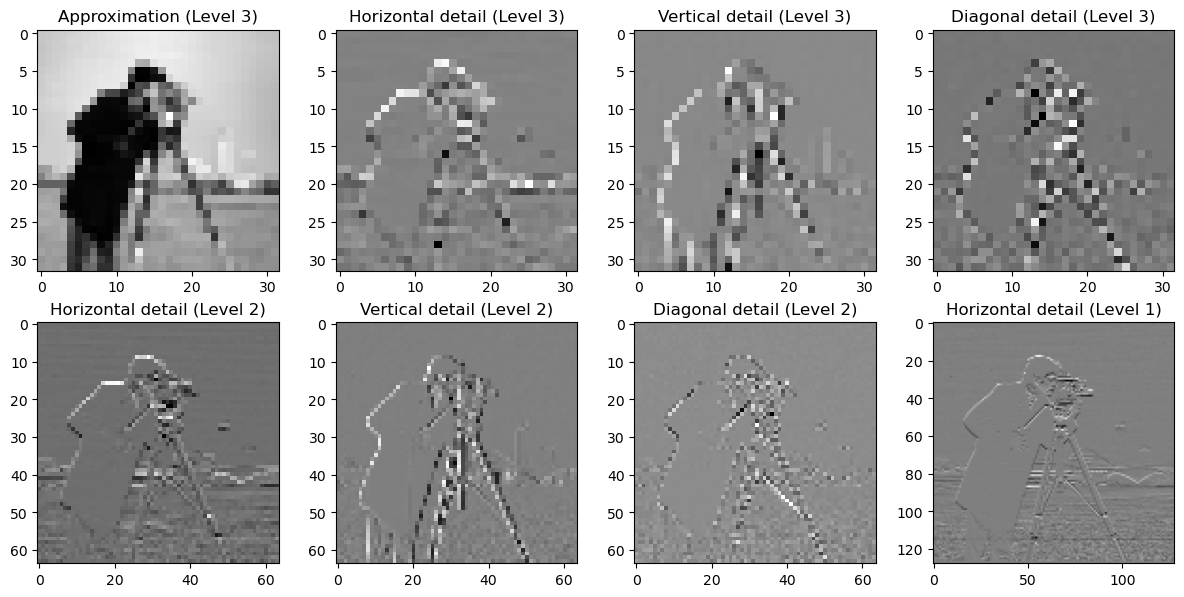

In [3]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(image, 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


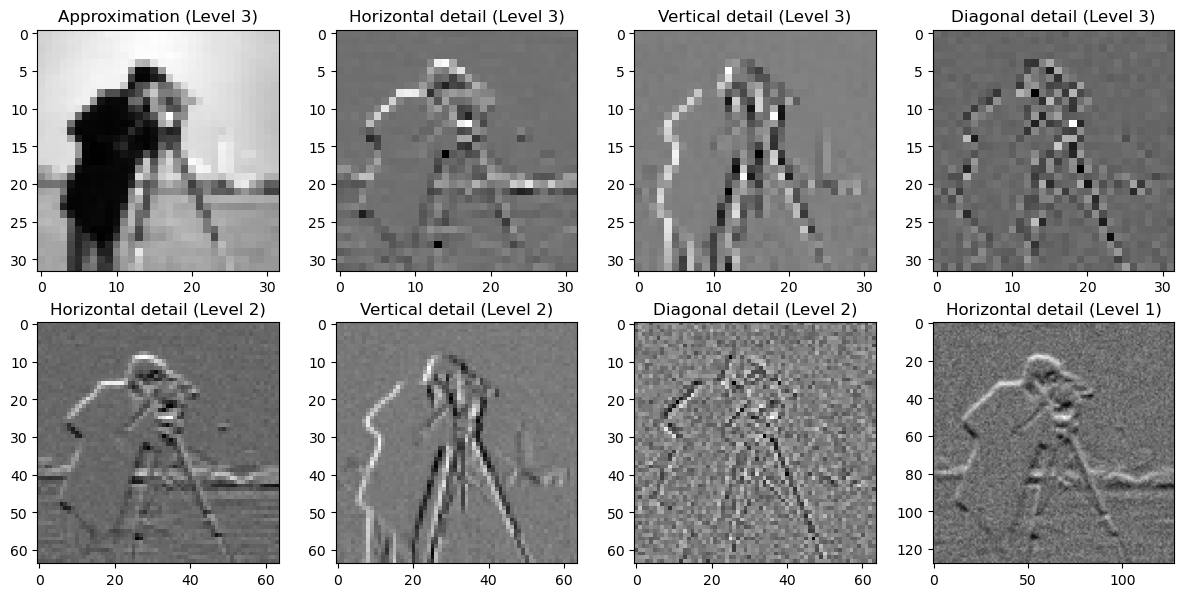

In [4]:
# Create a sample 2D image (e.g., 256x256 random matrix)

# Perform 2D wavelet decomposition using Haar wavelet, with 3 levels
coeffs = pywt.wavedec2(b.reshape(img_shape), 'haar', level=3)

# coeffs is a list containing the approximation coefficients and detail coefficients
# The first element of coeffs is the approximation coefficient at level 3
# The subsequent elements are tuples of detail coefficients (horizontal, vertical, diagonal) for each level

# Extract the approximation coefficients at the final level (level 3)
cA3 = coeffs[0]

# Extract the detail coefficients (cH, cV, cD) for each level
(cH3, cV3, cD3), (cH2, cV2, cD2), (cH1, cV1, cD1) = coeffs[1:]

# Plotting the approximation and detail coefficients for visualization
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

# Level 3 coefficients
ax[0, 0].imshow(cA3, cmap='gray')
ax[0, 0].set_title('Approximation (Level 3)')

ax[0, 1].imshow(cH3, cmap='gray')
ax[0, 1].set_title('Horizontal detail (Level 3)')

ax[0, 2].imshow(cV3, cmap='gray')
ax[0, 2].set_title('Vertical detail (Level 3)')

ax[0, 3].imshow(cD3, cmap='gray')
ax[0, 3].set_title('Diagonal detail (Level 3)')

# Level 2 coefficients
ax[1, 0].imshow(cH2, cmap='gray')
ax[1, 0].set_title('Horizontal detail (Level 2)')

ax[1, 1].imshow(cV2, cmap='gray')
ax[1, 1].set_title('Vertical detail (Level 2)')

ax[1, 2].imshow(cD2, cmap='gray')
ax[1, 2].set_title('Diagonal detail (Level 2)')

# Level 1 coefficients
ax[1, 3].imshow(cH1, cmap='gray')
ax[1, 3].set_title('Horizontal detail (Level 1)')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()


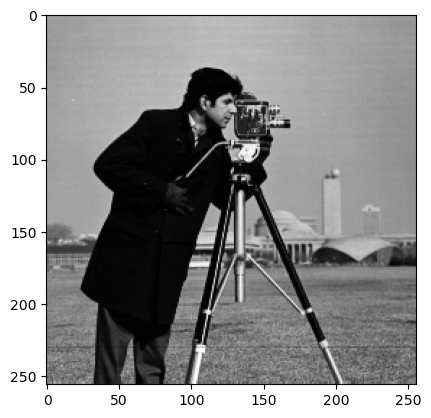

In [5]:
plt.imshow(image, cmap="gray")
plt.show()

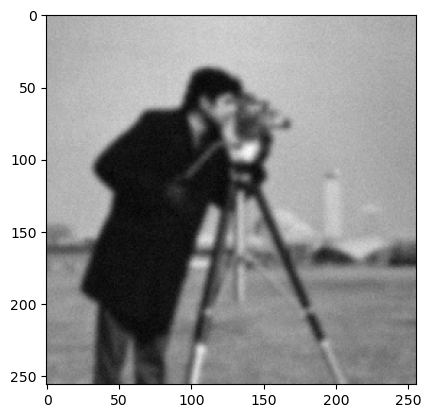

In [6]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

# Set up prior

In [13]:
# This can be figured out later
# mask = np.zeros(Lpre.shape[0])
# mask[ Lpre.detail_indices ] = 1
# P = jlinops.Subsampling1DOperator(mask)
#L = P @ Lpre

L = WaveletTransformOperator2D(img_shape, wavelet="haar", level=3)
K = None
Lpinv_factory = lambda wr: L.T @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

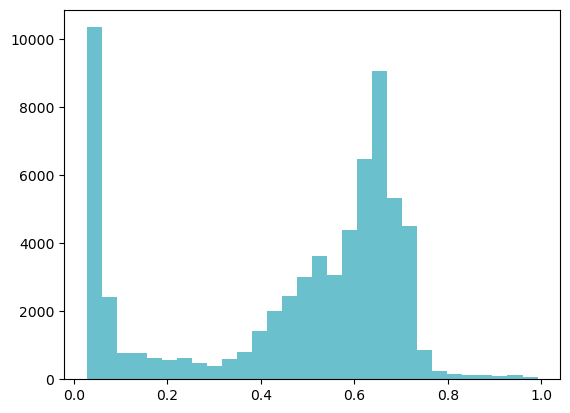

In [14]:
plt.hist(ground_truth, bins=30)
plt.show()

In [9]:
# Set method
method = "dp"

xker = None


# Weight params
q = 1.0

mm_weight_params_2019 = {
    "tau1": 1e-10,
    "tau2": 1e-16,
    "q": q,
}

ias_weight_params = {
    "hyperpr_r": -1,
    "hyperpr_beta": 1,
}

### Build solvers

# GKS solver
gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# MM solvers
mmgks_solver = MM2019GKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfkx_solver = MM2019FGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mmfk2019_solver = MM2019FGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape)
mmgkb_solver = MM2019GKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# IAS solvers
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
iasfkx_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
iasfk2019_solver = IASFGK2019(A, L, L.T, b, noise_var=noise_var, K=K, img_shape=img_shape)
iasgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

In [10]:
n_its = 150


# GKS
vdata = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params={},
                                    regparam_kwargs={"eta":1.01},  xker=xker)

# MM PS-GKS
mmpsgkspdata = mmgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=mm_weight_params_2019, 
                                                 regparam_kwargs={"eta":1.01})

# MM S-GKS
mmsgksdata = mmgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=mm_weight_params_2019,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


# MM FKX
mmfkxdata = mmfkx_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# MM FK2019 I
mmfk2019Idata = mmfk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# MM FK2019 R
mmfk2019Rdata = mmfk2019_solver.solve(n_iter=n_its, x0=None, mode="R", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# MM FK2019 W (IRW-FLSQR)
mmfk2019Wdata = mmfk2019_solver.solve(n_iter=n_its, x0=None, mode="W", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


# MM GKB 
mmgkbdata = mmgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=mm_weight_params_2019, lambdah_min=1e-7, lambdah_max=1e7
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

print("Finished P-GKB")







# IAS PS-GKS
iaspsgkspdata = iasgks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=ias_weight_params, 
                                                 regparam_kwargs={"eta":1.01})

# IAS S-GKS
iassksdata = iasgks_solver.solve(n_iter=n_its, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)


# IAS FKX
iasfkdata = iasfkx_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# IAS FK2019 I
iasfk2019Idata = iasfk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# IAS FK2019 R
mmfk2019Rdata = iasfk2019_solver.solve(n_iter=n_its, x0=None, mode="R", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

# IAS FK2019 W (IRW-FLSQR)
iasfk2019Wdata = iasfk2019_solver.solve(n_iter=n_its, x0=None, mode="W", lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=1e-7, lambdah_max=1e7,
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )


# MM GKB 
iasgkbdata = iasgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=None, weight_params=ias_weight_params, lambdah_min=1e-7, lambdah_max=1e7
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )




6.524887864084313
24.59172818329932
30.896015682368574
34.50144531882019
36.713818872729085
38.146198615775475
39.13395281060137
39.84422897949993
40.33842914159393
40.69576940234169
40.95531104295202
41.14413518873878
41.28039748729675
41.37869840834109
41.44662557804249
41.49603322861471
41.531229816586375
41.556257637348345
41.573911925350025
41.58645542500973
41.59542101787844
41.60136934096547
41.605527349581514
41.60851868263916
41.61060664594983
41.61205005904721
41.61306854268224
41.61378443926117
41.614269111415666
41.61460785157823
41.614834181562756
41.61499451598975
41.61510755971205
41.6151855917415
41.61524005344617
41.615276914249165
41.615302696062784
41.61532036592765
41.615332300207776
41.615340106118374
41.61534572917999
41.615349713129326
41.61535240722203
41.61535420074933
41.61535546143557
41.61535632843556
41.61535692739681
41.615357328805786
41.61535760454537
41.61535779281716
41.61535792283209
41.61535801427427
41.61535807612577
41.615358117007816
41.6153581449

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/tests/2d_blur_wavelets/../../msolver.py:800: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
5.206096726638112
7.441360261985242
8.93108333035084
10.14571882196469
11.228170362466788
12.19093107958424
12.988654581818603
13.614912174099256
14.160216592506304
14.638094720657651
15.083870086485982
15.499911758841469
15.86407947015245
16.17976658228247
16.499786200283364
16.777882051042955
17.014467085553544
17.248588618911935
17.508901775182277
17.77733436568233
18.009290057695754
18.201730984140532
18.395673191010395
18.57910491064541
18.732855765674532
18.865935171187257
18.971936842129352
19.06050481104799
19.13293643152593
19.191182113475808
19.2295779593276

42.940269504020925
20.091796523321555
30.651516972478348
21.022077770824847
24.482611037540217
22.32874558607991
22.698697924567675
19.88717246788271
22.91568002709892
22.313206318116126
22.890830636897476
23.44558889263736
22.04766506398776
22.172335512033808
21.89675535131136
22.14451625836056
21.542973673980025
21.60330473369907
21.714092754602763
21.504103497640642
21.569128216713352
20.505785177336364
20.761273973121238
20.40605836655358
20.663573431911175
20.39415903399419
20.25664958538077
20.080368202615844
20.247787596933268
20.665189406761495
20.435165367032404
20.480879779649435
21.055040346800805
21.1093866435074
21.105693782754734
21.043332786537295
21.602995462566696
21.678886564276787
21.798738143651583
21.727953615598988
21.768131373988002
21.598537602716956
21.675260592356604
21.756656509096167
21.803899483212234
21.870599821099237
21.593482159758917
21.686052460873043
21.441580236121833
21.550568321006217
21.61399957075404
21.55122636374638
21.26260901787315
20.897981

...

124.15561508349056



generating basis...: 100%|██████████| 149/149 [00:02<00:00, 57.78it/s]

190.86465593592905



generating basis...: 100%|██████████| 150/150 [00:02<00:00, 57.54it/s]

207.52759026563547


# Plots

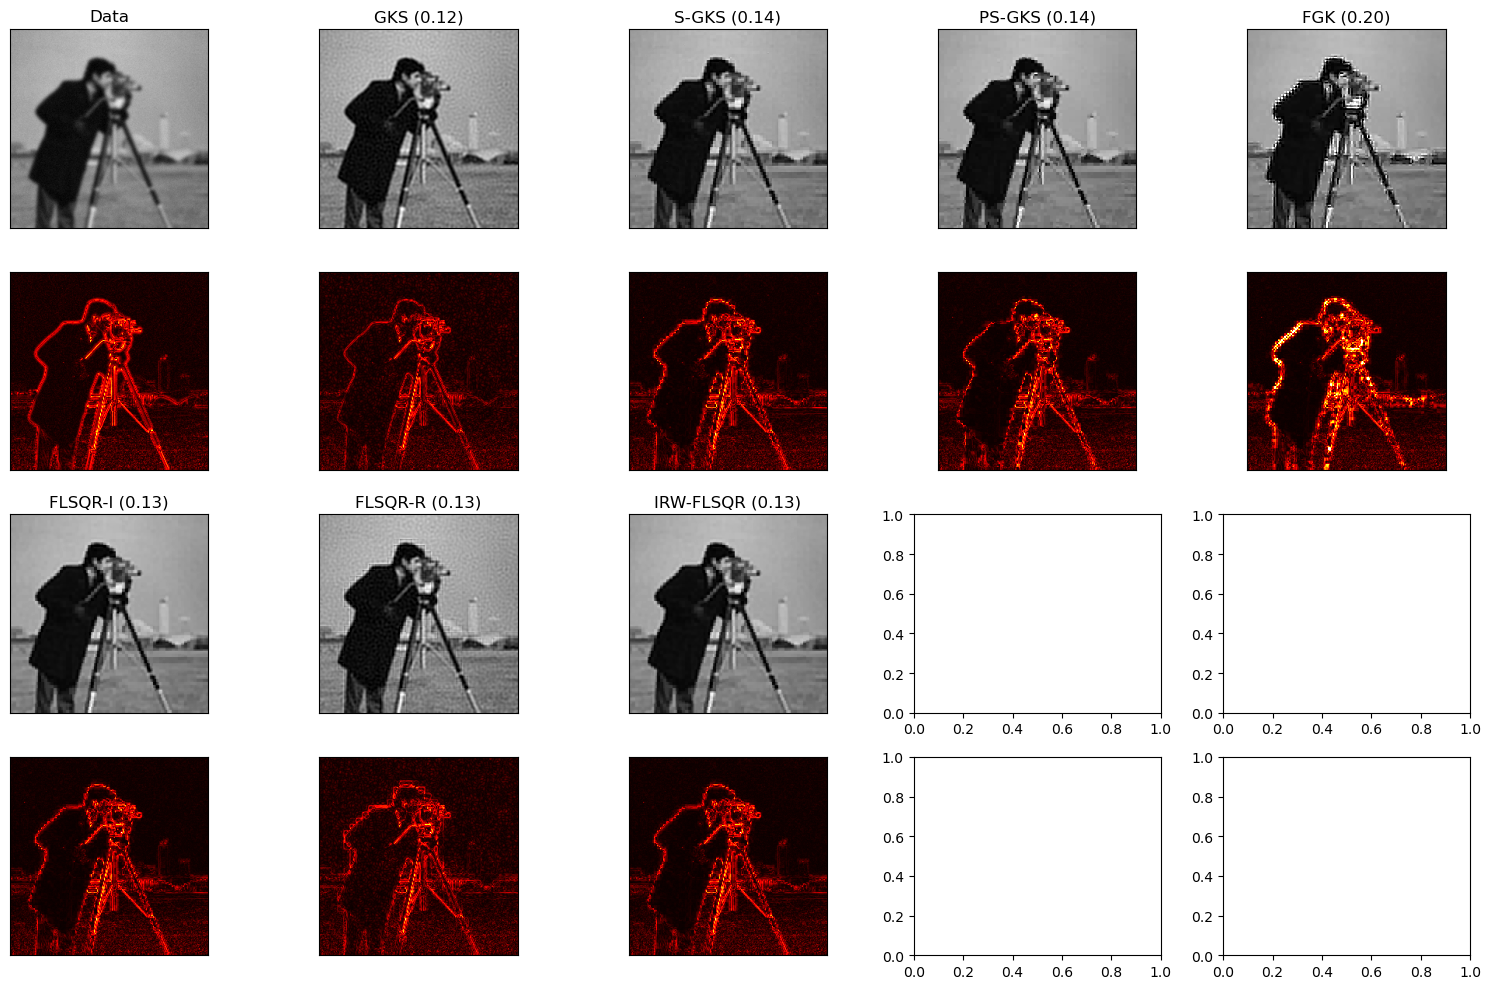

In [25]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(4,5,figsize=(15.3,10))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = vdata["rre_history"][-1]
axs[0,1].set_title(f"GKS ({rre:.2f})")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(mmsgksdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmsgksdata["rre_history"][-1]
axs[0,2].set_title(f"S-GKS ({rre:.2f})")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( mmsgksdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(mmpsgkspdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmpsgkspdata["rre_history"][-1]
axs[0,3].set_title(f"PS-GKS ({rre:.2f})")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( mmpsgkspdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkxdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfkxdata["rre_history"][-1]
axs[0,4].set_title(f"FGK ({rre:.2f})")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkxdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# FLSQR-I
axs[2,0].imshow(mmfk2019Idata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfk2019Idata["rre_history"][-1]
axs[2,0].set_title(f"FLSQR-I ({rre:.2f})")
axs[2,0].set_xticks([])
axs[2,0].set_yticks([])

axs[3,0].imshow(np.abs( mmfk2019Idata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,0].set_xticks([])
axs[3,0].set_yticks([])




# FLSQR-R
axs[2,1].imshow(mmfk2019Rdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfk2019Rdata["rre_history"][-1]
axs[2,1].set_title(f"FLSQR-R ({rre:.2f})")
axs[2,1].set_xticks([])
axs[2,1].set_yticks([])

axs[3,1].imshow(np.abs( mmfk2019Rdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,1].set_xticks([])
axs[3,1].set_yticks([])



# FLSQR-W
axs[2,2].imshow(mmfk2019Wdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
rre = mmfk2019Wdata["rre_history"][-1]
axs[2,2].set_title(f"IRW-FLSQR ({rre:.2f})")
axs[2,2].set_xticks([])
axs[2,2].set_yticks([])

axs[3,2].imshow(np.abs( mmfk2019Wdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[3,2].set_xticks([])
axs[3,2].set_yticks([])




# # PS-GKS restarting
# im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
# axs[0,5].set_title("P-GKB")
# axs[0,5].set_xticks([])
# axs[0,5].set_yticks([])
# divider = make_axes_locatable(axs[0,5])
# cax = divider.append_axes("right", size="5%", pad=0.05)
# fig.colorbar(im, cax=cax)

# im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
# axs[1,5].set_xticks([])
# axs[1,5].set_yticks([])
# divider = make_axes_locatable(axs[1,5])
# cax = divider.append_axes("right", size="5%", pad=0.00)
# fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_camera_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

[]

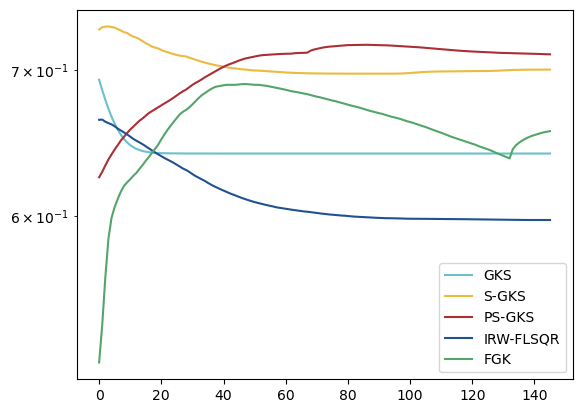

In [26]:
start_idx = 5
# metric = "rre_history"
metric = "ssim_history"

plt.semilogy(vdata[metric][start_idx:], label="GKS")
plt.semilogy(mmsgksdata[metric][start_idx:], label="S-GKS")
plt.semilogy(mmpsgkspdata[metric][start_idx:], label="PS-GKS")
plt.semilogy(mmfk2019Rdata[metric][start_idx:], label="IRW-FLSQR")
plt.semilogy(mmfkxdata[metric][start_idx:], label="FGK")
plt.legend()
plt.plot()

[]

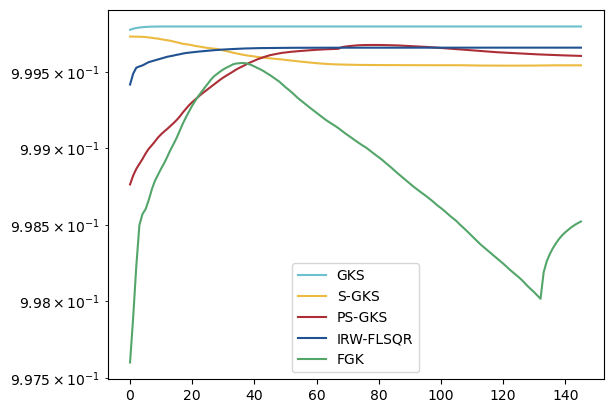

In [29]:
start_idx = 5
# metric = "rre_history"
metric = "haar_history"

plt.semilogy(vdata[metric][start_idx:], label="GKS")
plt.semilogy(mmsgksdata[metric][start_idx:], label="S-GKS")
plt.semilogy(mmpsgkspdata[metric][start_idx:], label="PS-GKS")
plt.semilogy(mmfk2019Rdata[metric][start_idx:], label="IRW-FLSQR")
plt.semilogy(mmfkxdata[metric][start_idx:], label="FGK")
plt.legend()
plt.plot()

In [28]:
vdata.keys()

dict_keys(['x', 'w', 'lambdah', 'tot_matvec_A', 'tot_matvec_L', 'residual_history', 'lambda_history', 'V', 'cond_ests', 'dp_ineq_lhs', 'dp_ineq_rhs', 'dp_ineq_chs', 'rre_history', 'ssim_history', 'haar_history'])

# Performance

NameError: name 'vdata' is not defined

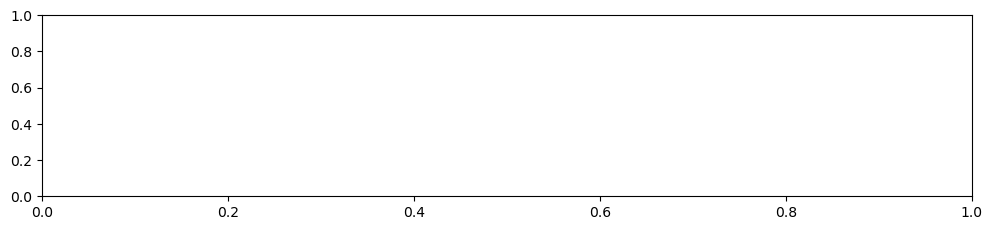

In [24]:
fig = plt.figure(figsize=(12,8) )

gs = gridspec.GridSpec(3, 2, figure=fig)

start_idx = 5
marker = ">"
markerfacecolor = 'none'

ax4 = fig.add_subplot(gs[0, :])
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))],  vdata["rre_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["rre_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["rre_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["rre_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
# ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["rre_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Idata["rre_history"][start_idx:], label="FLSQR-I", color="C9", marker="o", markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Rdata["rre_history"][start_idx:], label="FLSQR-I", color="C9", marker="^", markerfacecolor=markerfacecolor)
ax4.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Wdata["rre_history"][start_idx:], label="FLSQR-W", color="C9", marker="<", markerfacecolor=markerfacecolor)
ax4.legend()
ax4.set_xlabel("Iteration index")
ax4.set_title("RRE history")



ax3 = fig.add_subplot(gs[1, :])
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], vdata["ssim_history"][start_idx:], label="GKS", color="C3", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], data["ssim_history"][start_idx:], label="S-GKS", color="C5", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], pdata["ssim_history"][start_idx:], label="PS-GKS", color="C4", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfkdata["ssim_history"][start_idx:], label="FGK", color="C6", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmgkbdata["ssim_history"][start_idx:], label="P-GKB", color="C1", marker=marker, markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Idata["ssim_history"][start_idx:], label="FLSQR-I", color="C9", marker="o", markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Rdata["ssim_history"][start_idx:], label="FLSQR-I", color="C9", marker="^", markerfacecolor=markerfacecolor)
ax3.semilogy([i for i in range(start_idx, len(vdata["rre_history"]))], mmfk2019Wdata["ssim_history"][start_idx:], label="FLSQR-W", color="C9", marker="<", markerfacecolor=markerfacecolor)
ax3.legend()
ax3.set_xlabel("Iteration index")
ax3.set_title("SSIM history")

# ax3 = fig.add_subplot(gs[1, :])
# ax3.semilogy(vdata["haar_history"][start_idx:], label="GKS")
# ax3.semilogy(data["haar_history"][start_idx:], label="S-GKS")
# ax3.semilogy(pdata["haar_history"][start_idx:], label="PS-GKS")
# ax3.semilogy(mmfkdata["haar_history"][start_idx:], label="FGK")
# ax3.semilogy(mmgkbdata["haar_history"][start_idx:], label="P-GKB")
# ax3.legend()


ax1 = fig.add_subplot(gs[2, 0])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(mmfkdata["lambda_history"], label="FGK", color="C6")
ax1.semilogy(mmgkbdata["lambda_history"], label="P-GKB", color="C1")
ax1.legend(loc="lower right")
ax1.set_title("History of $\lambda$")
ax1.set_xlabel("Iteration index")



ax2 = fig.add_subplot(gs[2, 1])
ax2.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax2.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax2.semilogy(pdata["cond_ests"], label="PS-GKS", color="C4")
ax2.semilogy(mmfkdata["cond_ests"], label="FGK", color="C6")
ax2.semilogy(mmgkbdata["cond_ests"], label="P-GKB", color="C1")
ax2.legend(loc="upper left")
ax2.set_title("History of condition number")
ax2.set_xlabel("Iteration index")

fig.tight_layout()
fig.savefig("2d_camera_performance_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

# Reconstruction

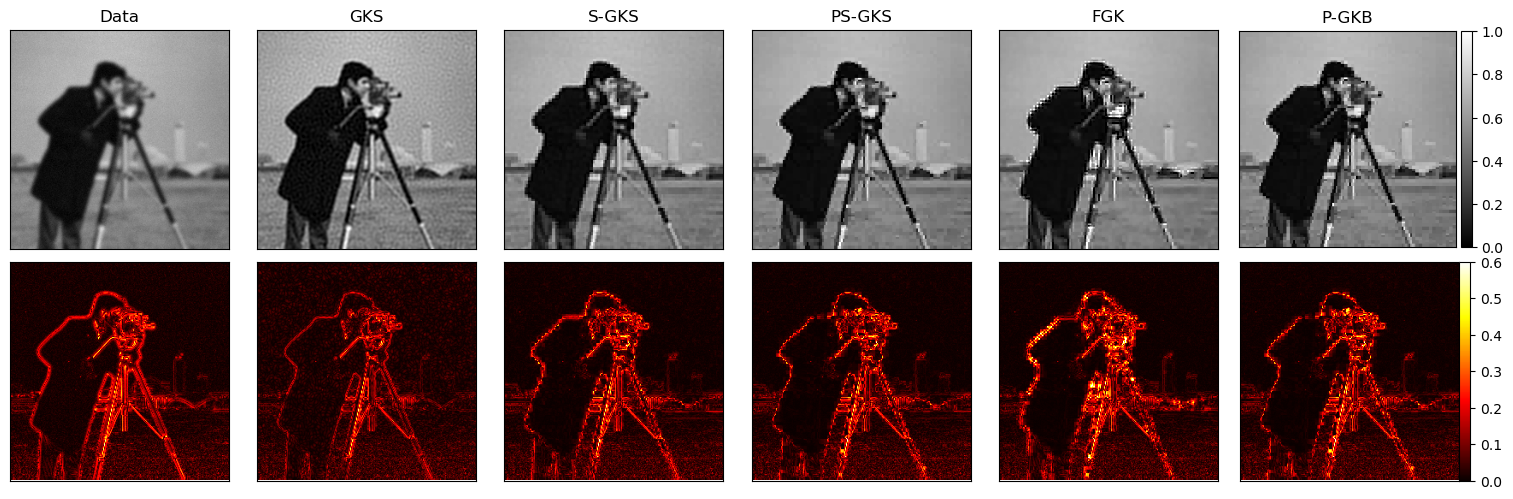

In [239]:
err_cmap = "hot"

vbound = 0.6

fig, axs = plt.subplots(2,6,figsize=(15.3,5))


# Observed
axs[0,0].imshow(b.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("Data")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( b.reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])



# Tikhonov
axs[0,1].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("GKS")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( vdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS
axs[0,2].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( data["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])


# FGK
axs[0,4].imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("FGK")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])

axs[1,4].imshow(np.abs( mmfkdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])



# PS-GKS restarting
im = axs[0,5].imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,5].set_title("P-GKB")
axs[0,5].set_xticks([])
axs[0,5].set_yticks([])
divider = make_axes_locatable(axs[0,5])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,5].imshow(np.abs(mmgkbdata["x"].reshape(img_shape) - ground_truth.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,5].set_xticks([])
axs[1,5].set_yticks([])
divider = make_axes_locatable(axs[1,5])
cax = divider.append_axes("right", size="5%", pad=0.00)
fig.colorbar(im, cax=cax)

fig.tight_layout()

fig.savefig("2d_camera_reconstructions_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_reconstructions_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

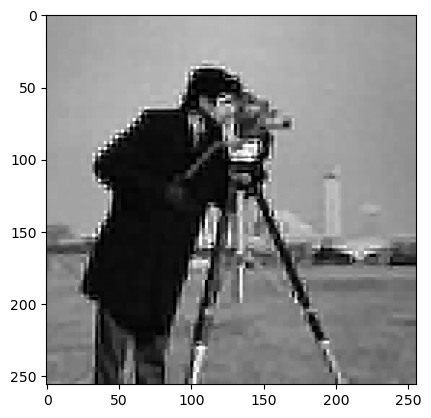

In [11]:
plt.imshow( (mmfkdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

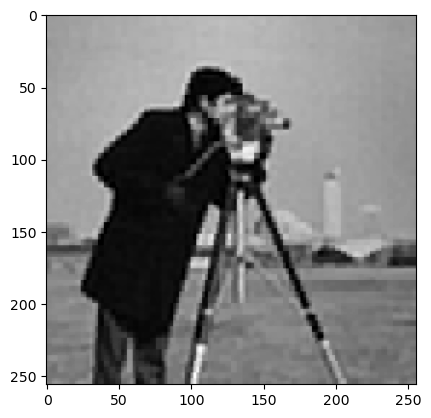

In [11]:
plt.imshow( (mmfk2019Wdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

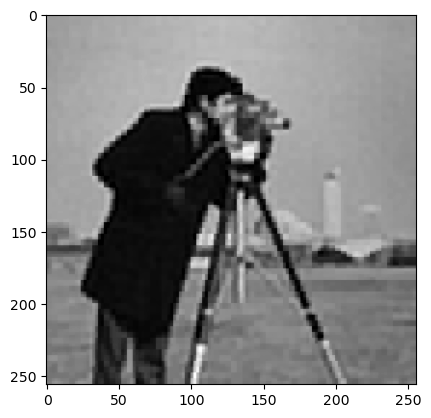

In [12]:
plt.imshow( (mmfk2019Idata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

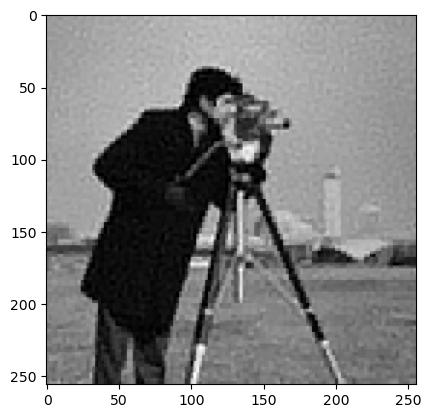

In [14]:
plt.imshow( (mmfk2019Rdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

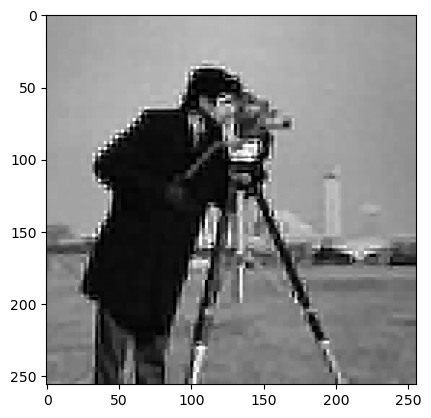

In [15]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
plt.show()

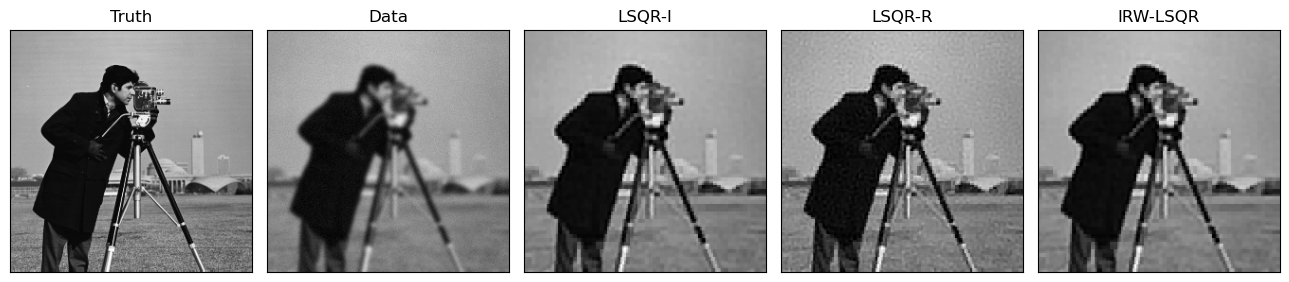

In [48]:
fig, axs = plt.subplots(1,5, figsize=(13,8))

axs[0].imshow(ground_truth.reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Truth")
axs[0].set_xticks([])
axs[0].set_yticks([])

axs[1].imshow((b).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Data")
axs[1].set_xticks([])
axs[1].set_yticks([])

axs[2].imshow( (mmfk2019Idata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[2].set_title("LSQR-I")
axs[2].set_xticks([])
axs[2].set_yticks([])

axs[3].imshow( (mmfk2019Rdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[3].set_title("LSQR-R")
axs[3].set_xticks([])
axs[3].set_yticks([])

axs[4].imshow( (mmfk2019Wdata["x"]).reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[4].set_title("IRW-LSQR")
axs[4].set_xticks([])
axs[4].set_yticks([])

fig.tight_layout()

plt.show()

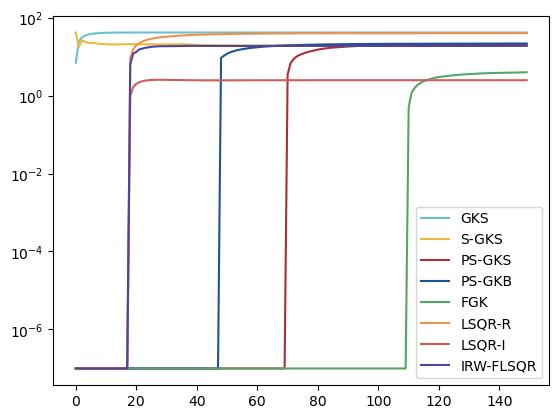

In [54]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmgkbdata["lambda_history"], label="PS-GKB")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmfk2019Rdata["lambda_history"], label="LSQR-R")
plt.semilogy(mmfk2019Idata["lambda_history"], label="LSQR-I")
plt.semilogy(mmfk2019Wdata["lambda_history"], label="IRW-FLSQR")
plt.legend()
plt.show()

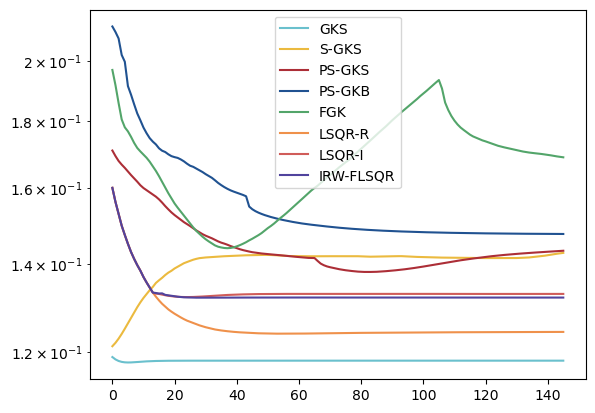

In [59]:
start_idx = 5
plt.semilogy(vdata["rre_history"][start_idx:], label="GKS")
plt.semilogy(data["rre_history"][start_idx:], label="S-GKS")
plt.semilogy(pdata["rre_history"][start_idx:], label="PS-GKS")
plt.semilogy(mmgkbdata["rre_history"][start_idx:], label="PS-GKB")
plt.semilogy(mmfkdata["rre_history"][start_idx:], label="FGK")
plt.semilogy(mmfk2019Rdata["rre_history"][start_idx:], label="LSQR-R")
plt.semilogy(mmfk2019Idata["rre_history"][start_idx:], label="LSQR-I")
plt.semilogy(mmfk2019Wdata["rre_history"][start_idx:], label="IRW-FLSQR")
plt.legend()
plt.show()

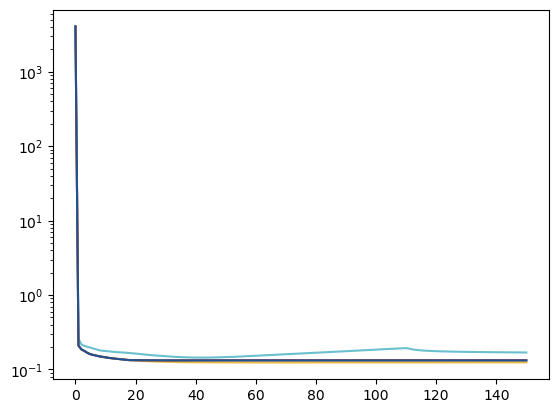

In [32]:
plt.semilogy(mmfkdata["rre_history"])
plt.semilogy(mmfk2019Rdata["rre_history"])
plt.semilogy(mmfk2019Idata["rre_history"])
plt.semilogy(mmfk2019Wdata["rre_history"])
plt.show()

# Basis vectors

In [154]:
np.amax(np.abs(data["V"][:,:]))

0.1890169249359265

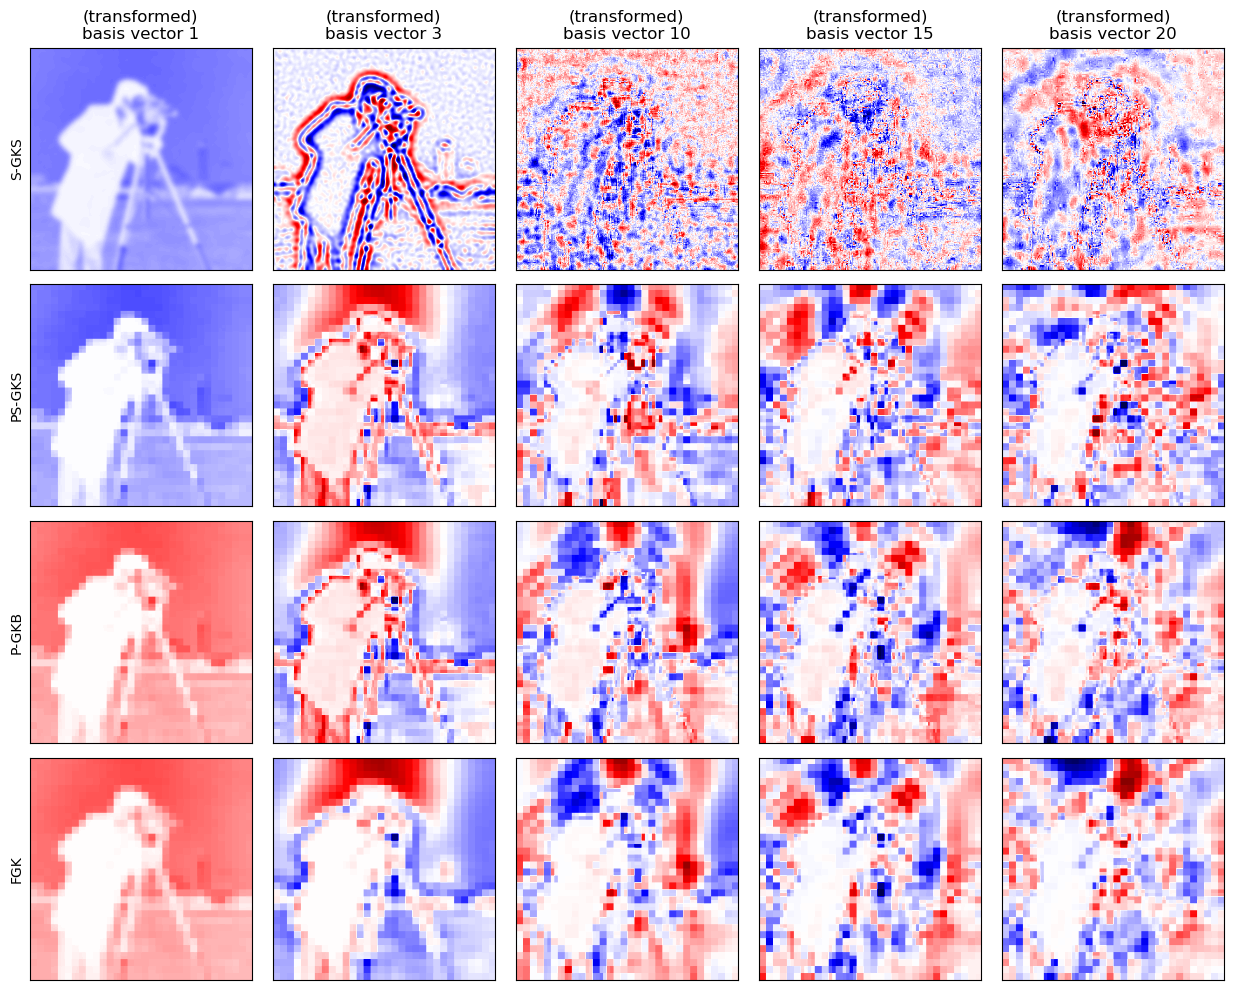

In [170]:
cmap = "seismic"
vbound = 0.1*0.189

kks = [0, 2, 9, 14, 19]

fig, axs = plt.subplots(4,5,figsize=(12.5,10))

for j, kk in enumerate(kks):

    axs[0,j].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[0,j].set_title(f"S-GKS basis vector {kk+1}")
    axs[0,j].set_xticks([])
    axs[0,j].set_yticks([])
    if j == 0:
        axs[0,0].set_ylabel(f"S-GKS")
    axs[0,j].set_title(f"(transformed)\nbasis vector {kk+1}")


for j, kk in enumerate(kks):

    axs[1,j].imshow( ( (pdata["Lopinv"] @ pdata["V"][:,kk])/np.linalg.norm(pdata["Lopinv"] @ pdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[1,j].set_xticks([])
    axs[1,j].set_yticks([])
    if j == 0:
        axs[1,j].set_ylabel(f"PS-GKS")


for j, kk in enumerate(kks):

    axs[2,j].imshow( ( (mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk])/np.linalg.norm(mmgkbdata["Lopinv"] @ mmgkbdata["V"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[2,j].set_xticks([])
    axs[2,j].set_yticks([])
    if j == 0:
        axs[2,j].set_ylabel(f"P-GKB")



for j, kk in enumerate(kks):

    axs[3,j].imshow( ( mmfkdata["Z"][:,kk]/np.linalg.norm(mmfkdata["Z"][:,kk]) ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
    axs[3,j].set_xticks([])
    axs[3,j].set_yticks([])
    if j == 0:
        axs[3,j].set_ylabel(f"FGK")


fig.tight_layout()

fig.savefig("2d_camera_basis_vectors_mm.png", dpi=250, bbox_inches=None)
fig.savefig("2d_camera_basis_vectors_mm.eps", format="eps", dpi=250, bbox_inches=None)


plt.show()

NameError: name 'resdata' is not defined

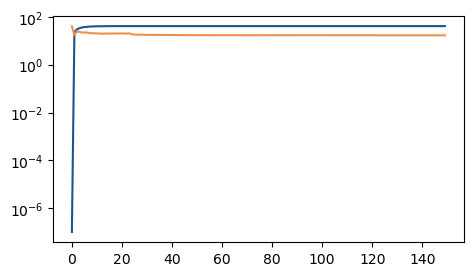

In [20]:
fig = plt.figure(figsize=(18,10))

gs = gridspec.GridSpec(3, 3, figure=fig)

ax1 = fig.add_subplot(gs[2, 2])
ax1.semilogy(vdata["lambda_history"], label="GKS", color="C3")
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C5")
ax1.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax1.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C4")
ax1.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 0])
ax2.semilogy(vdata["rre_history"], label="GKS", color="C3")
ax2.semilogy(data["rre_history"], label="S-GKS", color="C5")
ax2.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax2.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax2.semilogy(pdata["rre_history"], label="PS-GKS", color="C4")
ax2.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 1])
ax3.semilogy(vdata["ssim_history"], label="GKS")
ax3.semilogy(data["ssim_history"], label="S-GKS", color="C5")
ax3.semilogy(resdata["ssim_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax3.semilogy(recdata["ssim_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax3.semilogy(pdata["ssim_history"], label="PS-GKS", color="C4")
ax3.semilogy(respdata["ssim_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()



ax7 = fig.add_subplot(gs[0, 2])
ax7.semilogy(vdata["haar_history"], label="GKS")
ax7.semilogy(data["haar_history"], label="S-GKS", color="C5")
ax7.semilogy(resdata["haar_history"], label="S-GKS (restarting)", color="C5", ls="--")
ax7.semilogy(recdata["haar_history"], label="S-GKS (recycling)", color="C5", ls=":")
ax7.semilogy(pdata["haar_history"], label="PS-GKS", color="C4")
ax7.semilogy(respdata["haar_history"], label="PS-GKS (restarting)", color="C4", ls="--")
ax7.set_title("HaarPSI")
ax7.set_xlabel("Iteration index")
ax7.legend()




ax5 = fig.add_subplot(gs[1, :2]) 
ax5.semilogy(1.0/resdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax5.semilogy(1.0/respdata["w"][:int(len(resdata["w"])/2)].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax5.set_xlabel("Horizontal cross section at index 128")
ax5.set_title("$1/w$")
ax5.legend()



ax6 = fig.add_subplot(gs[1, 2])
ax6.semilogy(vdata["cond_ests"], label="GKS", color="C3")
ax6.semilogy(data["cond_ests"], label="S-GKS", color="C5")
ax6.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", color="C5", ls="--")
ax6.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", color="C5", ls=":")
ax6.semilogy(pdata["cond_ests"], label="PS-GKS", color="C2")
ax6.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", color="C4", ls="--")
ax6.set_title("Condition number")
ax6.set_xlabel("Iteration index")
ax6.legend()





ax4 = fig.add_subplot(gs[2, :2]) 
ax4.plot(x_true.reshape(img_shape)[128,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(vdata["x"].reshape(img_shape)[128,:], label="GKS", color="C3", ls="--")
ax4.plot(resdata["x"].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C5", ls="--")
ax4.plot(respdata["x"].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C4", ls="--")
ax4.set_xlabel("Horizontal cross section at index 128")
ax4.legend()



fig.tight_layout()
# fig.savefig("2d_shepp_performance_mm.png", dpi=250, bbox_inches=None)
# fig.savefig("2d_shepp_performance_mm.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

# Other plots

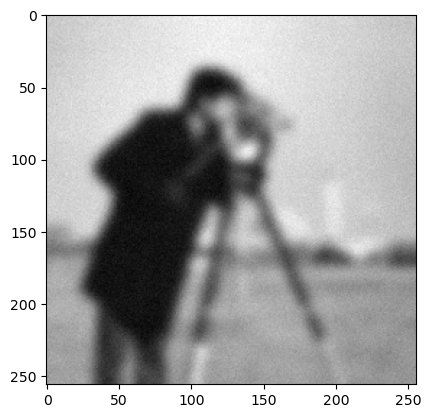

In [135]:
plt.imshow(b.reshape(img_shape), cmap="gray")
plt.show()

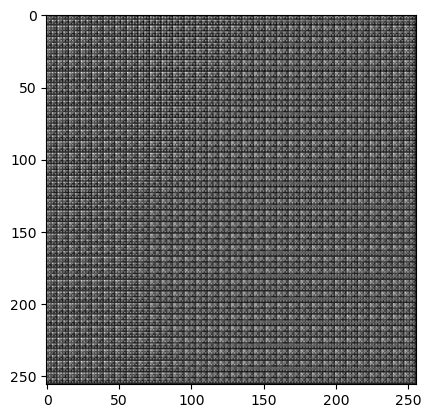

In [136]:
plt.imshow( (L.T @ b).reshape(img_shape), cmap="gray")
plt.show()

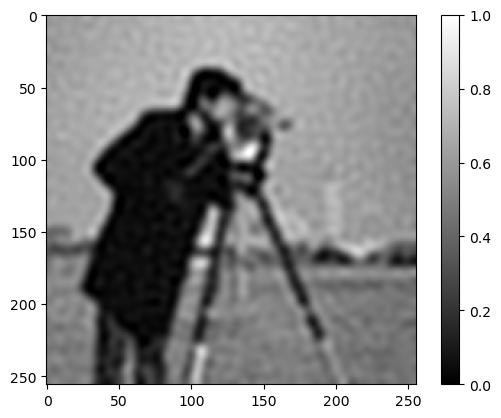

In [116]:
plt.imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

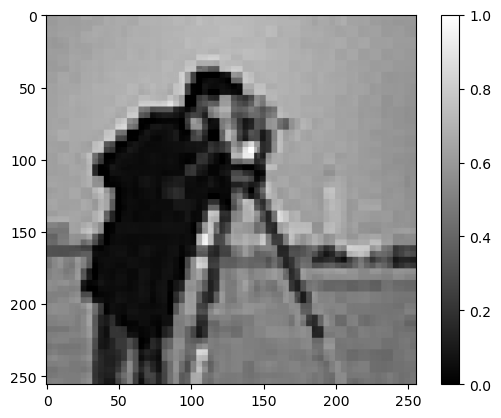

In [117]:
plt.imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

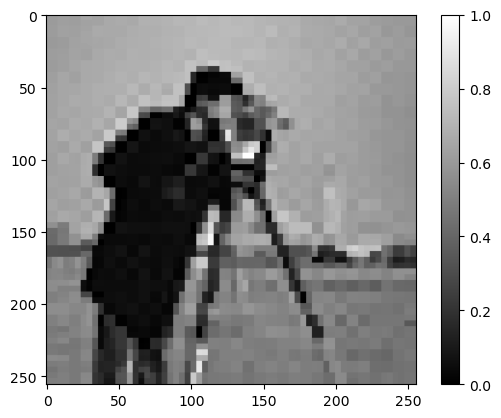

In [118]:
plt.imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

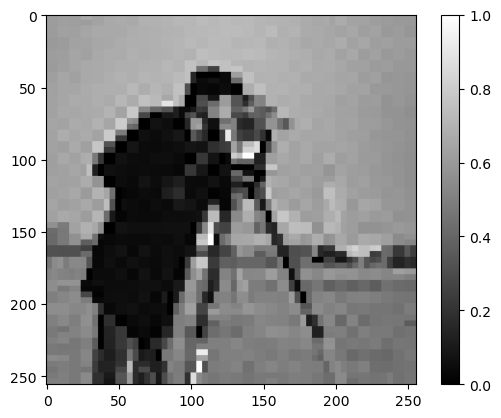

In [119]:
plt.imshow(mmgkbdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

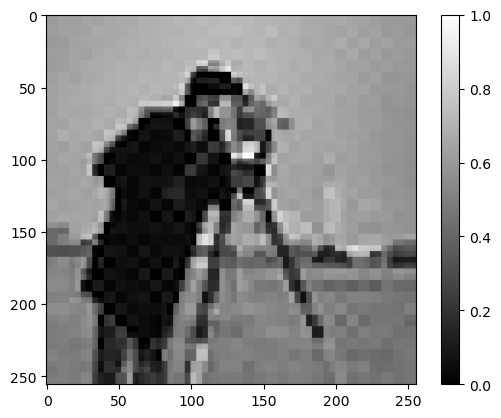

In [120]:
plt.imshow(mmfkdata["x"].reshape(img_shape), cmap="gray", vmin=0.0, vmax=1.0)
plt.colorbar()
plt.show()

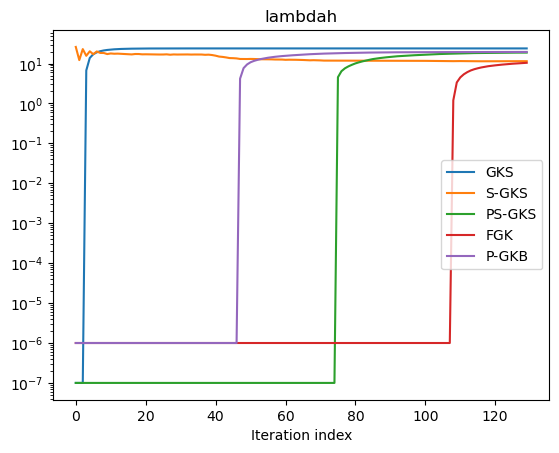

In [121]:
plt.semilogy(vdata["lambda_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["lambda_history"], label="PS-GKS")
plt.semilogy(mmfkdata["lambda_history"], label="FGK")
plt.semilogy(mmgkbdata["lambda_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("lambdah")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

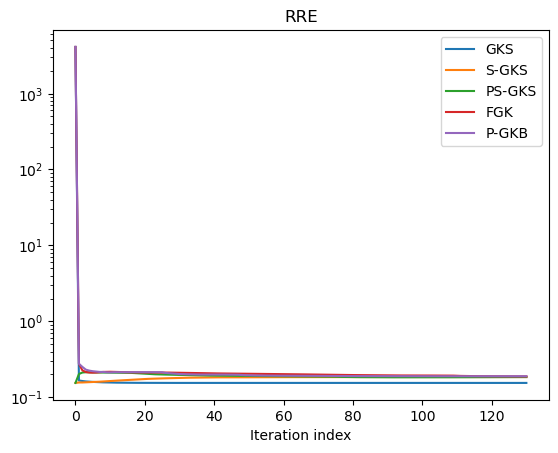

In [122]:
plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["rre_history"], label="PS-GKS")
plt.semilogy(mmfkdata["rre_history"], label="FGK")
plt.semilogy(mmgkbdata["rre_history"], label="P-GKB")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

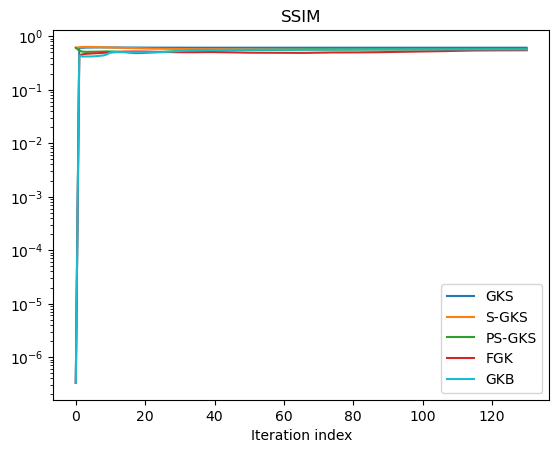

In [125]:
plt.semilogy(vdata["ssim_history"], label="GKS")
plt.semilogy(data["ssim_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pdata["ssim_history"], label="PS-GKS")
plt.semilogy(mmfkdata["ssim_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(mmgkbdata["ssim_history"], label="GKB", color="C9")
plt.title("SSIM")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

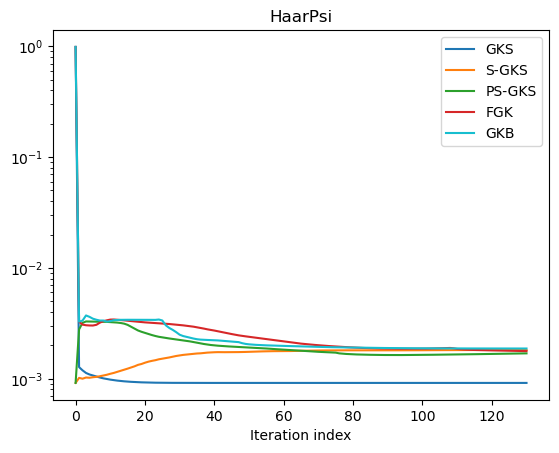

In [126]:
plt.semilogy(1-vdata["haar_history"], label="GKS")
plt.semilogy(1-data["haar_history"], label="S-GKS")
# plt.semilogy(data_opt["rre_history"], label="S-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(1-pdata["haar_history"], label="PS-GKS")
plt.semilogy(1-mmfkdata["haar_history"], label="FGK")
# plt.semilogy(pdata_opt["rre_history"], label="PS-GKS (optimal)", ls="--", alpha=0.7)
#plt.semilogy(rdata["rre_history"], label="Restarted", ls="--", alpha=0.7)
plt.semilogy(1-mmgkbdata["haar_history"], label="GKB", color="C9")
plt.title("HaarPsi")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [24]:
pdata["haar_history"]

array([0.99977895, 0.99893879, 0.99877378, 0.99870822, 0.99871015,
       0.9987684 , 0.99883229, 0.99887182, 0.99890467, 0.99893616,
       0.99896992, 0.99899804, 0.99902043, 0.99904554, 0.99907053,
       0.99909251, 0.99911082, 0.99912711, 0.99914394, 0.99916236,
       0.99918311, 0.99920906, 0.99923647, 0.99926293, 0.99928414,
       0.9993028 , 0.99932018, 0.99933764, 0.99935618, 0.99937194,
       0.99938765, 0.99940613, 0.99942366, 0.99944045, 0.99945714,
       0.99947115, 0.99948362, 0.99949556, 0.99950773, 0.99951852,
       0.99952721, 0.99953537, 0.99954417, 0.99955255, 0.99956083,
       0.99956818, 0.99957536, 0.99958231, 0.9995889 , 0.99959529,
       0.99960063, 0.99960472, 0.99960906, 0.99961346, 0.99961734,
       0.99962098, 0.99962459, 0.99962742, 0.99962972, 0.9996319 ,
       0.99963382, 0.99963526, 0.99963669, 0.99963862, 0.99964097,
       0.99964298, 0.99964476, 0.99964625, 0.99964718, 0.99964826,
       0.99965394, 0.99966057, 0.99966447, 0.99966765, 0.99967

In [25]:
vdata["haar_history"]

array([9.31203851e-04, 9.99680055e-01, 9.99707518e-01, 9.99728855e-01,
       9.99744216e-01, 9.99755268e-01, 9.99762842e-01, 9.99768336e-01,
       9.99772198e-01, 9.99774815e-01, 9.99776571e-01, 9.99777668e-01,
       9.99778344e-01, 9.99778713e-01, 9.99778885e-01, 9.99778956e-01,
       9.99778968e-01, 9.99778972e-01, 9.99778982e-01, 9.99779013e-01,
       9.99779031e-01, 9.99779029e-01, 9.99779020e-01, 9.99779011e-01,
       9.99779003e-01, 9.99778992e-01, 9.99778986e-01, 9.99778977e-01,
       9.99778971e-01, 9.99778966e-01, 9.99778962e-01, 9.99778960e-01,
       9.99778961e-01, 9.99778962e-01, 9.99778961e-01, 9.99778960e-01,
       9.99778958e-01, 9.99778957e-01, 9.99778955e-01, 9.99778954e-01,
       9.99778953e-01, 9.99778952e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
       9.99778951e-01, 9.99778951e-01, 9.99778951e-01, 9.99778951e-01,
      

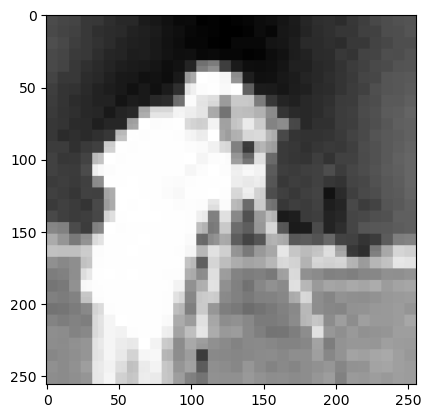

In [127]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

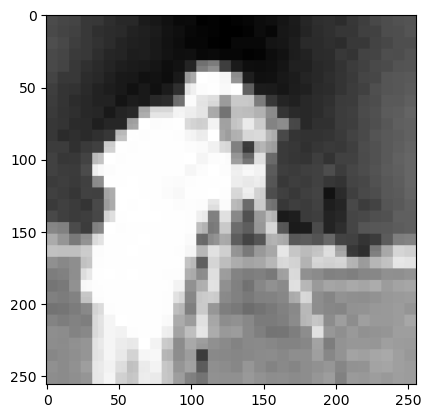

In [128]:
plt.imshow( (pdata["Lopinv"] @ pdata["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

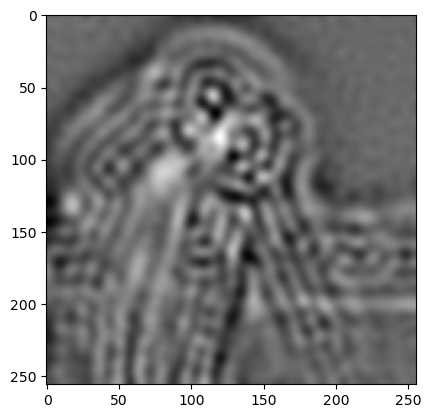

In [129]:
plt.imshow( (vdata["V"][:,5]).reshape(img_shape) , cmap="gray")
plt.show()

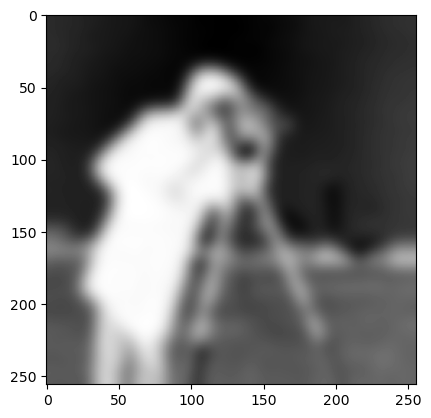

In [130]:
plt.imshow( (data["V"][:,0]).reshape(img_shape) , cmap="gray")
plt.show()

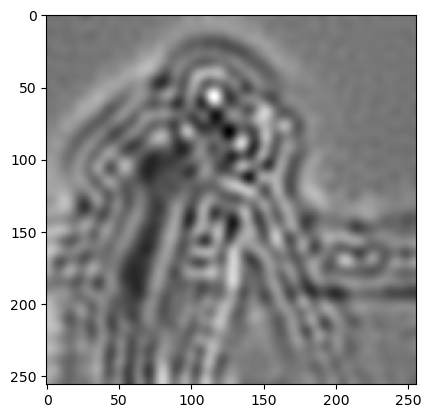

In [131]:
plt.imshow( (data["V"][:,4]).reshape(img_shape) , cmap="gray")
plt.show()

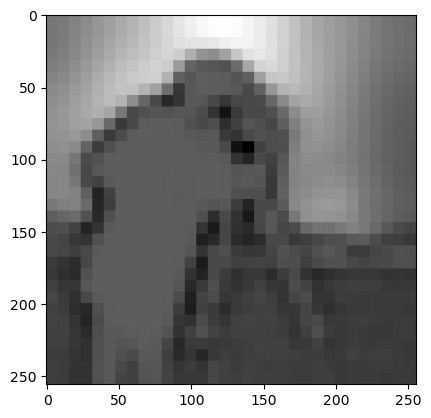

In [132]:
plt.imshow( (mmfkdata["Z"][:,1]).reshape(img_shape) , cmap="gray")
plt.show()

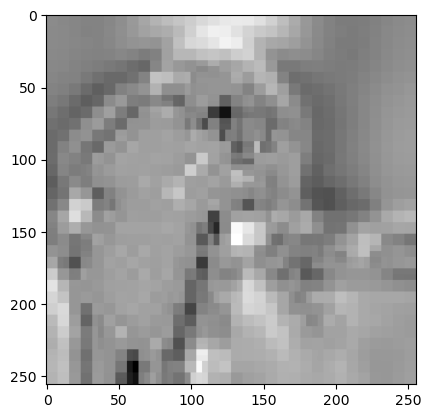

In [133]:
plt.imshow( (mmgkbdata["Lopinv"] @ ( (mmgkbdata["V"][:,4]) ) ).reshape(img_shape) , cmap="gray")
plt.show()

In [134]:
mmgkbdata.keys()

dict_keys(['x', 'V', 'U', 'B', 'w', 'Lopinv', 'lambda_history', 'cond_ests', 'rre_history', 'ssim_history', 'haar_history'])